In [1]:
import numpy as np
import time
from scipy.io import savemat
import scipy
from opencosmorspy import Parameterization, COSMORS
import math
import os

N = 100
delta = 1. / N

polymers = ['polychloroprene', 'polydimethylsiloxane', 'polyepichlorohydrin', 'polystyrene', 'polyvinylacetate', 'polybutadiene']
solvents = ['Acetone', 'Acetonitrile', 'Benzene', 'Chloroform', 'Cyclohexane', 'Ethanol', 'Methanol', 'THF', 'Toluene']
temperatures = {'polychloroprene_Acetone': 100, 'polychloroprene_Acetonitrile': 100, 'polychloroprene_Benzene': 100, 'polychloroprene_Chloroform': 100, 'polychloroprene_Cyclohexane': 100, 'polychloroprene_Ethanol': 100, 'polychloroprene_Methanol': 100, 'polychloroprene_THF': 100, 'polychloroprene_Toluene': 100, 
                'polydimethylsiloxane_Acetone': 100, 'polydimethylsiloxane_Acetonitrile': 100, 'polydimethylsiloxane_Benzene': 20, 'polydimethylsiloxane_Chloroform': 100, 'polydimethylsiloxane_Cyclohexane': 100, 'polydimethylsiloxane_Ethanol': 100, 'polydimethylsiloxane_Methanol': 100, 'polydimethylsiloxane_THF': 100, 'polydimethylsiloxane_Toluene': 100,
                'polyepichlorohydrin_Acetone': 100, 'polyepichlorohydrin_Acetonitrile': 100, 'polyepichlorohydrin_Benzene': 100, 'polyepichlorohydrin_Chloroform': 100, 'polyepichlorohydrin_Cyclohexane': 100, 'polyepichlorohydrin_Ethanol': 100, 'polyepichlorohydrin_Methanol': 100, 'polyepichlorohydrin_THF': 100, 'polyepichlorohydrin_Toluene': 100,
                'polystyrene_Acetone': 25, 'polystyrene_Acetonitrile': 162, 'polystyrene_Benzene': 40, 'polystyrene_Chloroform': 40, 'polystyrene_Cyclohexane': 40, 'polystyrene_Ethanol': 162, 'polystyrene_Methanol': 162, 'polystyrene_THF': 162, 'polystyrene_Toluene': 162,
                'polyvinylacetate_Acetone': 100, 'polyvinylacetate_Acetonitrile': 125, 'polyvinylacetate_Benzene': 125, 'polyvinylacetate_Chloroform': 80, 'polyvinylacetate_Cyclohexane': 100, 'polyvinylacetate_Ethanol': 100, 'polyvinylacetate_Methanol': 125, 'polyvinylacetate_THF': 100, 'polyvinylacetate_Toluene': 80,
                'polybutadiene_Acetone': 40, 'polybutadiene_Acetonitrile': 40, 'polybutadiene_Benzene': 40, 'polybutadiene_Chloroform': 40, 'polybutadiene_Cyclohexane': 40, 'polybutadiene_Ethanol': 40, 'polybutadiene_Methanol': 40, 'polybutadiene_THF': 40, 'polybutadiene_Toluene': 40}

for poly_prefix in polymers:
    for solvent_prefix in solvents:
        with open('volume_list.txt', 'r') as volume_file:
            lines = volume_file.readlines()
        v = np.zeros(2)
        for line in lines:
            split_line = line.split()
            if split_line[0] == poly_prefix:
                v[0] = float(split_line[1])
            elif split_line[0] == solvent_prefix:
                v[1] = float(split_line[1])

        print(f"delta: {delta}")
        print(f"Volumes of molecules: {v}")

        def normalize_and_adjust_mol_fractions(mol_fractions, tolerance=1e-16):
            mol_fractions = np.array(mol_fractions, dtype=np.float64)
            total = np.sum(mol_fractions)
            normalized_mol_fractions = mol_fractions / total
            
            # Check if the sum meets the required precision
            sum_normalized = np.sum(normalized_mol_fractions)
            if abs(1.0 - sum_normalized) > tolerance:
                # Adjust the last element to correct the rounding error
                normalized_mol_fractions[-1] += 1.0 - sum_normalized
            return normalized_mol_fractions

        with open(f'indices_files/indices2phases.txt', 'w') as file:
            with open(f'indices_files/input-cosmors-2phases.py', 'w') as file2:
                for ia in range(0, N+1):
                        ib = N - ia
                        if ia+ib == N and ib >= 0:
                            a = ia * delta
                            b = ib * delta
                            sum_v = a / v[0] + b / v[1]
                            am = a / v[0] * 1 / sum_v
                            bm = b / v[1] * 1 / sum_v
                            normalized_mol_fractions = normalize_and_adjust_mol_fractions([am,bm])
                            print(f"{ia:.0f} {ib:.0f}", file=file)
                            print(f"\nx = np.array([{normalized_mol_fractions[0]}, {normalized_mol_fractions[1]}]) \ncrs.add_job(x, T, refst='pure_component') ", file=file2)

        T = temperatures[f'{poly_prefix}_{solvent_prefix}'] + 273.15 # convert to Kelvin
        filename = f'{poly_prefix}_{solvent_prefix}.mat'

        crs = COSMORS(par='default_orca')
        crs.par.calculate_contact_statistics_molecule_properties = True

        # define molecules
        crs.add_molecule([f'polymers/{poly_prefix}_{solvent_prefix}/run.cosmors'])
        crs.add_molecule([f'solvents/{solvent_prefix}/run.cosmors'])


        file_path = f'indices_files/input-cosmors-2phases.py'
        with open(file_path, 'r') as file:
            file_contents = file.read()
        exec(file_contents)
        results = crs.calculate()

        file_path = f'indices_files/indices2phases.txt'
        indices = np.loadtxt(file_path, dtype=int)  # Assuming the indices are integers

        maxN = np.max(indices) + 1  # Calculate the maximum value in indices
        lna = np.zeros((maxN, maxN, 2), dtype=float)  # Initialize lna

        for i in range(len(indices)):
            a = indices[i][0]
            b = indices[i][1]

            lnAs = results['enth']['lng'][i]
            lna[a, b, :] = np.array(lnAs)

        lna4 = lna.astype(float)
        lna4[np.isnan(lna)] = 0.0

        mdict = {'matrix': lna}

        # Directory where you want to save the file
        save_dir = "matrices"  # Change this to your desired folder
        os.makedirs(save_dir, exist_ok=True)  # Create the folder if it doesn't exist

        save_path = os.path.join(save_dir, filename)
        savemat(save_path, mdict)



delta: 0.01
Volumes of molecules: [2073.69136514  556.29894145]
delta: 0.01
Volumes of molecules: [2073.69136514  424.0055792 ]
delta: 0.01
Volumes of molecules: [2073.69136514  734.46672917]
delta: 0.01
Volumes of molecules: [2073.69136514  684.9643142 ]
delta: 0.01
Volumes of molecules: [2073.69136514  825.75119991]
delta: 0.01
Volumes of molecules: [2073.69136514  455.58918932]
delta: 0.01
Volumes of molecules: [2073.69136514  323.98319864]
delta: 0.01
Volumes of molecules: [2073.69136514  643.08238871]
delta: 0.01
Volumes of molecules: [2073.69136514  869.6511686 ]
delta: 0.01
Volumes of molecules: [2673.04577889  556.29894145]
delta: 0.01
Volumes of molecules: [2673.04577889  424.0055792 ]
delta: 0.01
Volumes of molecules: [2673.04577889  734.46672917]
delta: 0.01
Volumes of molecules: [2673.04577889  684.9643142 ]
delta: 0.01
Volumes of molecules: [2673.04577889  825.75119991]
delta: 0.01
Volumes of molecules: [2673.04577889  455.58918932]
delta: 0.01
Volumes of molecules: [2673.

In [2]:
import cvxpy as cp
import numpy as np
import matplotlib.pyplot as plt
import scipy

def find_optimal_chi_with_constraints(phi, L):
    """
    Finds the optimal symmetric CHI matrix that minimizes ||Phi * Chi - L||_F^2
    subject to Chi >= 0, Chi is symmetric, and the diagonal of Chi is zero.

    Parameters:
    - phi: numpy.ndarray, shape (4, 4)
    - L: numpy.ndarray, shape (4, 4)

    Returns:
    - Chi_opt: numpy.ndarray, shape (4, 4), the optimized CHI matrix
    """
    # Ensure that phi and L are numpy arrays
    phi = np.array(phi)
    L = np.array(L)

    # Define the CHI variable as symmetric with non-negativity constraints
    Chi = cp.Variable((2, 2), symmetric=True)

    # Define the constraints
    constraints = [
        cp.diag(Chi) == 0  # Zero diagonal
    ]

    # Define the objective function (Frobenius norm squared)
    objective = cp.Minimize(cp.norm(phi @ Chi - L, 'fro')**2)

    # Define the problem with the objective and constraints
    prob = cp.Problem(objective, constraints)

    # Solve the problem
    prob.solve()

    # Check if the problem was solved successfully
    if prob.status not in ["infeasible", "unbounded"]:
        Chi_opt = Chi.value
        return Chi_opt
    else:
        raise ValueError("Optimization problem is infeasible or unbounded.")

polymers = ['polychloroprene', 'polydimethylsiloxane', 'polyepichlorohydrin', 'polystyrene', 'polyvinylacetate', 'polybutadiene']
solvents = ['Acetone', 'Acetonitrile', 'Benzene', 'Chloroform', 'Cyclohexane', 'Ethanol', 'Methanol', 'THF', 'Toluene']


chi_list = []

for poly_prefix in polymers:
    for solvent_prefix in solvents:
        # Load the .mat file
        mu_data = scipy.io.loadmat(f"matrices/{poly_prefix}_{solvent_prefix}.mat")
        mu = mu_data['matrix']

        # Generate the increment indices
        mu_incr = np.arange(mu.shape[0])

        # Create a grid of indices
        i, j = np.meshgrid(mu_incr, mu_incr, indexing='ij')

        # Flatten the index arrays
        i_flat = i.ravel()
        j_flat = j.ravel()

        # Calculate the condition
        condition = (i_flat + j_flat) == (mu.shape[0] - 1)

        # Apply the condition to filter indices
        i_filtered = i_flat[condition]
        j_filtered = j_flat[condition]

        # Gather the corresponding mu values and steps
        mu_nonzero = mu[i_filtered, j_filtered, :]
        mu_step_temp = np.stack((i_filtered, j_filtered), axis=-1) / (mu.shape[0] - 1)

        # If want to fit chi to entire mu
        #   # with open('DFT_misc_polymers/volume_list.txt', 'r') as volume_file:
        #   #     lines = volume_file.readlines()
        #   # v = np.zeros(2)
        #   # for line in lines:
        #   #     split_line = line.split()
        #   #     if split_line[0] == poly_prefix:
        #   #         v[0] = float(split_line[1])
        #   #     elif split_line[0] == solvent_prefix:
        #   #         v[1] = float(split_line[1])
        #   # v_mult = np.array([1, v[0]/v[1]]) # reference volume is volume of polymer
        #   # # Find FH interaction parameters
        #   # PHI = mu_step_temp
        #   # L = mu_nonzero * v_mult
        #   # B = PHI.T @ L
        #   # A = PHI.T @ PHI
        #   # Chi_opt = find_optimal_chi_with_constraints(PHI, L)
        #   # print("Optimal CHI matrix with zero diagonal:")
        #   # print(f"{poly_prefix} in {solvent_prefix}: chi", Chi_opt[0, 1])
        #   # chi_list.append(Chi_opt[0, 1])

        # Paper evaluates chis we are considering in limit that polymer volume fraction in polymer-solvent mixture is 1 so only need this
        chi_list.append(mu_nonzero[-1, 1])

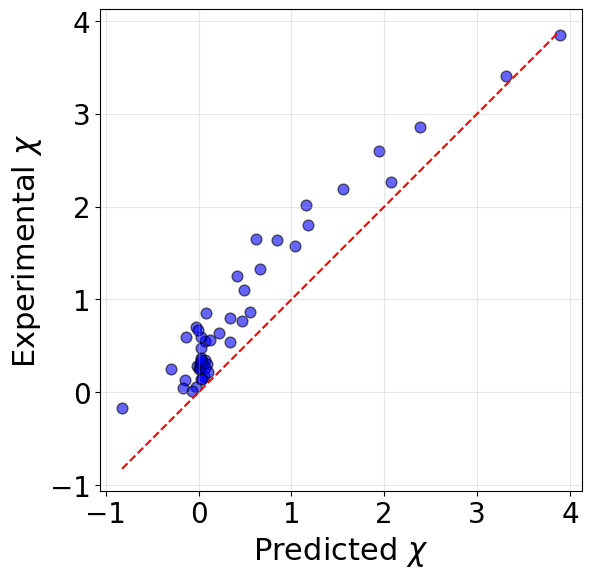

In [15]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FixedLocator


# Plot experimental versus predicted chi parameters
exp_chi = np.array([
                    0.87, np.nan, 0.18, 0.28, 0.55, 2.27, np.nan, 0.06, 0.14,
                    1.33, np.nan, 0.85, 0.60, 0.35, 2.6, np.nan, 0.48, 0.59,
                    0.28, np.nan, 0.25, 0.25, 1.25, 1.58, np.nan, 0.01, 0.31,
                    1.1, 2.02, 0.26, 0.13, 0.64, 1.80, 2.19, 0.70, 0.67,
                    0.32, 0.54, 0.37, -0.17, 1.65, 0.80, 0.77, 0.30, 0.56,
                    1.64, 2.86, 0.26, 0.05, 0.22, 3.41, 3.85, 0.35, 0.14
                    ])
pred_chi = np.array(chi_list)

# Plot
fig, ax = plt.subplots(figsize=(6, 6))

min_val = min(min(exp_chi), min(pred_chi))
max_val = max(max(exp_chi), max(pred_chi))
ax.plot([min_val, max_val], [min_val, max_val], label=r'\textbf{Perfect Agreement}', color='r', linestyle='--')

ax.scatter(pred_chi, exp_chi, color='blue', edgecolors='black', s=60, alpha=0.6)
ax.set_ylabel(r'Experimental $\chi$', fontsize=22)
ax.set_xlabel(r'Predicted $\chi$', fontsize=22)


# Square aspect ratio
ax.set_aspect('equal', adjustable='box')

# Set tick label font sizes
ax.tick_params(axis='both', which='major', labelsize=20)
# Pick ticks you want
ticks = np.linspace(-1, 4, 6)

ax.xaxis.set_major_locator(FixedLocator(ticks))
ax.yaxis.set_major_locator(FixedLocator(ticks))

ax.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.savefig('chi_polymer-solvent.png', dpi=300)


In [1]:
16/3

5.333333333333333